# 3Gyr Escaped Asteroid Analysis mc_pm6_3 
This notebooks is in preparation for the 3Gyr analysis and the new luthera family dataframe that includes more orbital information.

The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. 

This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 


In [1]:
import datetime as datetime
from pathlib import Path

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

xlabel_time = 'Years after start of simulation [$10^9 ~ yr$]'

project_dir = Path('../../asteroid_data/mc_pm6_3/')

plot_dir = project_dir / 'plots'


In [2]:
# Read the escaped asteroids file
ea_mmc3 = pd.read_hdf(project_dir / 'escaped_asteroids.h5')

# Strip the spaces out of the names of the asteroids
ea_mmc3['ast_name'] = [x.replace(' ','') for x in ea_mmc3.ast_name]

ea_mmc3.describe()

,particle_number,parameter,parameter_value,integration_year,min_val,max_val
count,36087.000000,36087.000000,36087.000000,3.608700e+04,36087.000000,36087.000000
mean,9.145648,6.716574,2.463010,5.643052e+09,0.319788,5.296246
std,0.837261,0.752043,5.720012,5.648621e+09,1.190401,10.044900
min,8.000000,6.000000,-2.071092,1.000000e+04,-153.251723,0.340019
25%,8.000000,6.000000,0.340329,6.726912e+08,0.000000,0.782868
50%,9.000000,7.000000,0.393295,3.442278e+09,0.000000,1.266282
75%,10.000000,7.000000,0.790637,9.770382e+09,0.046305,3.242661
max,10.000000,8.000000,98.535587,1.884954e+10,3.902529,98.535587


In [3]:
print(f"Mars/Ceres Mercurious escaped test-particles:{(ea_mmc3.ast_name+ea_mmc3['vectors']).nunique()}")


Mars/Ceres Mercurious escaped test-particles:19771


In [4]:
new_fam_dir = Path('../../luthera_ast/')

luth_proper_h5 = new_fam_dir / 'luther_proper.h5'
luth_fam = pd.read_hdf(luth_proper_h5)

luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])

mag_h = 17
p_v = 0.0387

luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
luth_fam = luth_fam.set_index('ast_name')
luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
count,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.0,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863,62.636725,163.961034,-74.485114,259.071526,-10.0,0.329816,18.897053,4.478502
std,0.987079,0.014558,0.008572,0.005743,0.426461,57.980031,1.524164,752.086762,0.0,0.006072,0.347883,3.757710
min,9.480000,3.172780,0.106420,0.312013,61.765176,85.871008,-79.056097,5.500000,-10.0,0.317312,18.180615,1.752546
25%,15.620000,3.196843,0.117742,0.320017,62.306345,118.604830,-75.573336,29.200000,-10.0,0.325747,18.663932,2.829238
50%,16.390000,3.207515,0.123102,0.323137,62.653273,146.082211,-74.454953,82.950000,-10.0,0.329043,18.852771,3.561800
75%,16.890000,3.219394,0.129977,0.327705,62.966784,194.958434,-73.310560,250.000000,-10.0,0.333874,19.129562,5.077729
max,17.930000,3.238196,0.144674,0.340954,63.701778,361.322776,-71.181669,10000.000000,-10.0,0.347932,19.935032,85.836005


In [5]:
old_luth_h5 = '../../asteroid_data/luthera_family.h5'

old_luth_fam = pd.read_hdf(old_luth_h5)
old_luth_fam = old_luth_fam.set_index('ast_name')
old_luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P
count,878.000000,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863
std,0.987079,0.014558,0.008572,0.005743
min,9.480000,3.172780,0.106420,0.312013
25%,15.620000,3.196843,0.117742,0.320017
50%,16.390000,3.207515,0.123103,0.323137
75%,16.890000,3.219394,0.129976,0.327705
max,17.930000,3.238196,0.144674,0.340954


## Data issues !!!
The proper elements (from afp.num.pro.txt and afp.mult.pro.txt) were merged into the family data (afp.fam.members.txt)
to provide the perihelion an nodal precessions (g and s).

We now have unmatched asteroids coming back from the simulations as they were run with the old asteroid designations.

From the afp.fam.members.txt dated 2023AUG08

| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | Family ID |
| --- | --- | --- | --- | --- | --- |
|  2017AC51 |  17.41   |   3.172780   |   0.120229   |   0.321580   |   1303 |

From the afp.fam.members.txt dated 2023FEB27
| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | Family ID |
| --- | --- | --- | --- | --- | --- |
| 2010VV146  |  17.41   |   3.172780   |   0.120229   |   0.321580    |  1303 |


From the afp.mult.pro.txt dated 2023AUG09

| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | n | g | s | lyap time | My Int Time |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2017AC51  |   17.41  | 3.1727797 | 0.1202292 | 0.3215795  | 63.701778  |  85.871008  | -71.650735  |     14.9  |  -10 |
| 2010VV146  |  17.83  | 2.8051083 | 0.1852427 | 0.0790516  | 76.607069  |  68.027468  | -72.775633   |   243.9   | -10 |

There are 


In [6]:
# Extract the unique ast_names
family_asts = luth_fam.index.unique()
# Extract the unique ast_names
old_family_asts = old_luth_fam.index.unique()

# get the list of asteroids that remained the same
in_common = family_asts.intersection(old_family_asts)

# Find the ones that are not in both (these are the duplicates)
old_missing = old_luth_fam.index.difference(in_common)
new_missing = luth_fam.index.difference(in_common)

# Sort the values by semi major axis and eccentricity to line up the asteroids with the same values
old_sort = old_luth_fam[old_luth_fam.index.isin(old_missing)].sort_values(['a_P','e_P'])
new_sort = luth_fam[luth_fam.index.isin(new_missing)].sort_values(['a_P','e_P'])

name_converter = [ (x[1], x[0]) for x in zip(list(new_sort.index),list(old_sort.index))]

#print(name_converter)
for convert in name_converter:
    # print(f'changing {convert[0]} to {convert[1]}')
    ea_mmc3.loc[(ea_mmc3.ast_name==convert[0]),'ast_name'] = convert[1]

ea_mmc3 = ea_mmc3.set_index('ast_name')

In [35]:
escaped_asts = ea_mmc3.index.unique()
print(f'Checking that all the escaped asts {len(escaped_asts)} = {len(luth_fam[luth_fam.index.isin(escaped_asts)==True])} are in the family')

print(escaped_asts[escaped_asts.isin(luth_fam.index)==False])
#print(ea_mmc3[ea_mmc3.index=='P_426'])

print(luth_fam[luth_fam.index.str.startswith('2021PF34')][['a_P', 'e_P','sineI_P','irad', 'ideg']])

print([ast_name for ast_name in name_converter if ast_name[0] in ['2012XW89', '2012QD29']])


Checking that all the escaped asts 691 = 690 are in the family
Index(['P_426'], dtype='object', name='ast_name')
               a_P       e_P   sineI_P      irad       ideg
ast_name                                                   
2021PF34  3.196374  0.133705  0.328545  0.334763  19.180493
[('2012QD29', '2020FU35'), ('2012XW89', '2021PF34')]


# Test Particle escape histogram

The number of particles that escape of the simulation period.



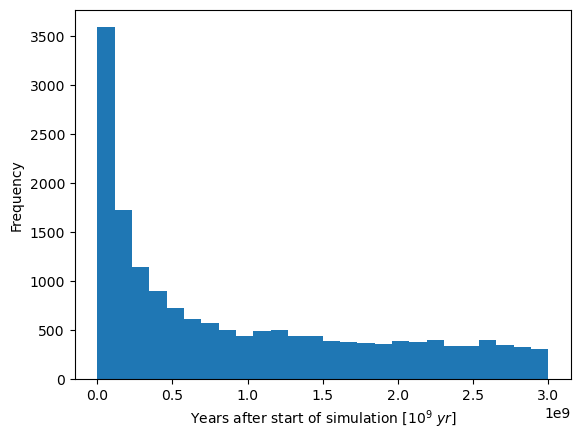

In [8]:
escapee_years = ea_mmc3.loc[ea_mmc3.parameter == 6][['vectors', 'integration_year']]
escapee_years['integration_year'] = escapee_years.integration_year/(2*np.pi)
part_nums, t_values, what = plt.hist(escapee_years.integration_year, bins='auto')
plt.ylabel('Frequency')
plt.xlabel(xlabel_time)
plt.savefig(plot_dir / "escape_hist.png", dpi=300)
plt.show()

# Calculating half-life of test-particle orbital disruption

From: *The Dynamical history of 2060 Chiron (Wood 2017)*

Using the standard radioactive decay formula of 

$N = N_0 ~e^{\frac{-0.693}{\tau}t}$

$N_0$ is the starting number of particles
$N$ is the remaining number of 

So we fit:  

$ln(\frac{N}{N_0}) = \frac{-0.693}{\tau}t$

$\frac{-0.693}{\tau} = \frac{ln(\frac{N}{N_0})}{t}$

$\tau = \frac{-0.693 \times t}{ln(\frac{N}{N_0})}$


The tau=1.33e+09 yr and the 99.99% time is 1.77e+10 yr


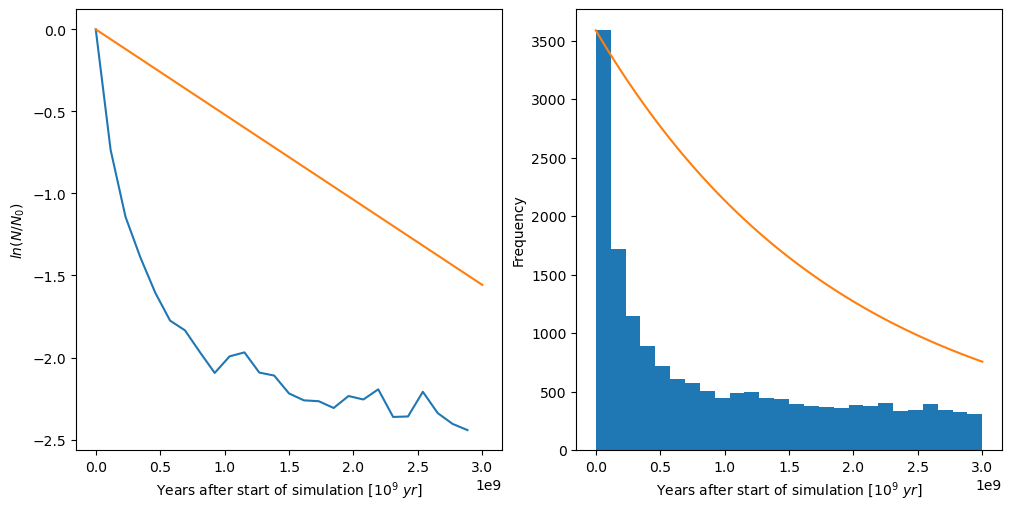

In [9]:
# Get the ratio of the particles
n_0 = part_nums[0]
t_span = np.linspace(0, t_values[-1], 100)

# linerize the ratios
ln_part_ratios = np.log(part_nums/n_0)
part_fit = np.polynomial.Polynomial.fit(t_values[:-1], ln_part_ratios, 1)
k, a = part_fit.convert().coef
ln_fit = t_span*a

fig = plt.figure(figsize=(10, 5), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

ax1.plot(t_values[:-1], ln_part_ratios)
ax1.plot(t_span, ln_fit)
ax1.set_ylabel(r'$ln(N/N_0)$')
ax1.set_xlabel(xlabel_time)

t=(-0.693/a)
n_fit = n_0 * np.e**((-0.693/t)*t_span)

# Calc long 99.99% loss time
n_9999 = n_0 * (1.0-0.9999)
t_9999 = (t*np.log(n_9999/n_0))/-0.693
print(f'The tau={t :0.2e} yr and the 99.99% time is {t_9999:0.2e} yr')

ax2 = fig.add_subplot(spec[0, 1])
ax2.hist(escapee_years.integration_year, bins='auto')
ax2.plot(t_span, n_fit)
ax2.set_ylabel('Frequency')
ax2.set_xlabel(xlabel_time)
plt.show()

# Size Frequency Distribution

Holt 2021, Nesvorny 2018 
It needs the estimated complete SFD for similar families or regions  


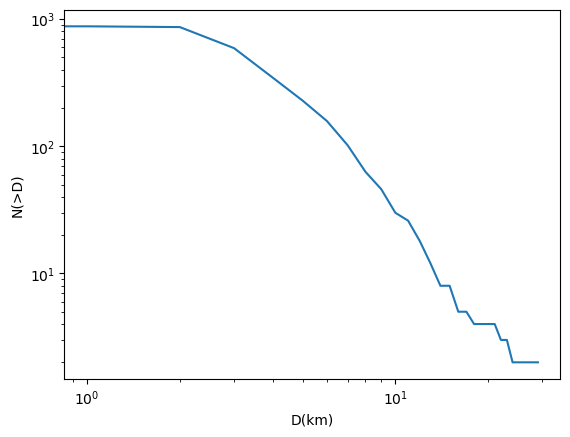

In [10]:

kms = list(range(0, 30)) #int(luth_fam.diam.max()+1)))

n_gt_km = [len(luth_fam[luth_fam.diam>km]) for km in kms]  
plt.plot(kms, n_gt_km)
plt.yscale('log')
plt.xscale('log')
plt.ylabel('N(>D)')
plt.xlabel('D(km)')
plt.show()

# Calculate the Mean escape year for each Asteroid

Also count how many of the 64 test particles for each asteroid escapes


In [11]:
ey_years = escapee_years.groupby(by=escapee_years.index)
mean_escape = ey_years.mean('integration_year')
mean_escape['vec_count'] = ey_years.vectors.count()

print(escapee_years.head())

print(mean_escape.head())

                        vectors  integration_year
ast_name                                         
16794     XcpYcmZcpVXcpVYcmVZcp      9.881132e+07
499395    XcpYcmZcpVXcpVYcmVZcp      9.891133e+07
2017EV28  XcpYcmZcpVXcpVYcmVZcp      8.651010e+07
499395    XcmYcpZcmVXcmVYcpVZcp      1.802193e+08
2017EV28  XcmYcpZcmVXcmVYcpVZcp      2.360391e+07
          integration_year  vec_count
ast_name                             
104287        1.570929e+09         26
107448        1.854844e+09         15
111276        1.763208e+09         12
111798        1.948073e+09         10
113406        2.136745e+09          3


In [12]:
counts, bins = np.histogram(mean_escape.vec_count, 4)
mean_escape['quartiles'] = np.digitize(mean_escape.vec_count, bins)

In [13]:
luth_fam['integration_year'] = mean_escape.integration_year
luth_fam['quartiles'] = mean_escape.quartiles

luth_fam = luth_fam.fillna(value={'integration_year': 0, 'vec_count': 0})
luth_fam['graph_symbol'] = '.'
luth_fam.loc[luth_fam['integration_year']!=0,['graph_symbol']] = 'o'
len(luth_fam[luth_fam['integration_year']!=0])

luth_fam

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam,integration_year,quartiles,graph_symbol
ast_name,,,,,,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,62.310603,193.693422,-75.178531,500.0,-10,0.328133,18.800642,85.836005,2.467311e+09,1.0,o
11911,11.80,3.210027,0.132169,0.330567,62.579772,151.725694,-75.054158,48.8,-10,0.336904,19.303169,29.489642,2.288327e+09,1.0,o
16794,13.45,3.229767,0.120773,0.321221,62.006408,267.491465,-76.751030,87.7,-10,0.327018,18.736764,13.793342,9.323623e+08,2.0,o
17840,12.46,3.227073,0.122213,0.322861,62.084582,243.861008,-76.365994,123.5,-10,0.328751,18.836035,21.760531,1.555482e+09,2.0,o
26558,13.15,3.194646,0.115763,0.319342,63.032408,116.103022,-72.503135,27.1,-10,0.325035,18.623155,15.836875,0.000000e+00,NaN,.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021TA55,17.17,3.194082,0.114092,0.317706,63.048004,115.703831,-72.437569,53.8,-10,0.323309,18.524232,2.486964,2.539433e+09,1.0,o
2021TZ86,17.04,3.199622,0.138950,0.332601,62.884899,122.499167,-74.946763,625.0,-10,0.339060,19.426734,2.640399,3.910643e+08,4.0,o
2021UJ60,17.20,3.194881,0.135663,0.334094,63.027298,111.565516,-73.689163,24.4,-10,0.340644,19.517454,2.452842,1.150835e+09,3.0,o


# Escape ratio and mean escape time of each asteroid



In [14]:
def flash_plot(ax, ast_data, y_column, x_column='a_P'):
    esc = stab = None
    for graph_symbol, m_fam in ast_data.groupby('graph_symbol'):
        if graph_symbol == '.':
            stab = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='white', marker='P', 
            c='black', label='Stable Asteroid')
        else:
            cm_yr = mpl.colormaps['inferno'] 
            norm_vecs = m_fam['quartiles']*40
            colour_values = m_fam['integration_year']
            esc = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='black', marker=graph_symbol, 
                c=colour_values, cmap = cm_yr, s=norm_vecs, label='Quartile')
    return esc, stab
                


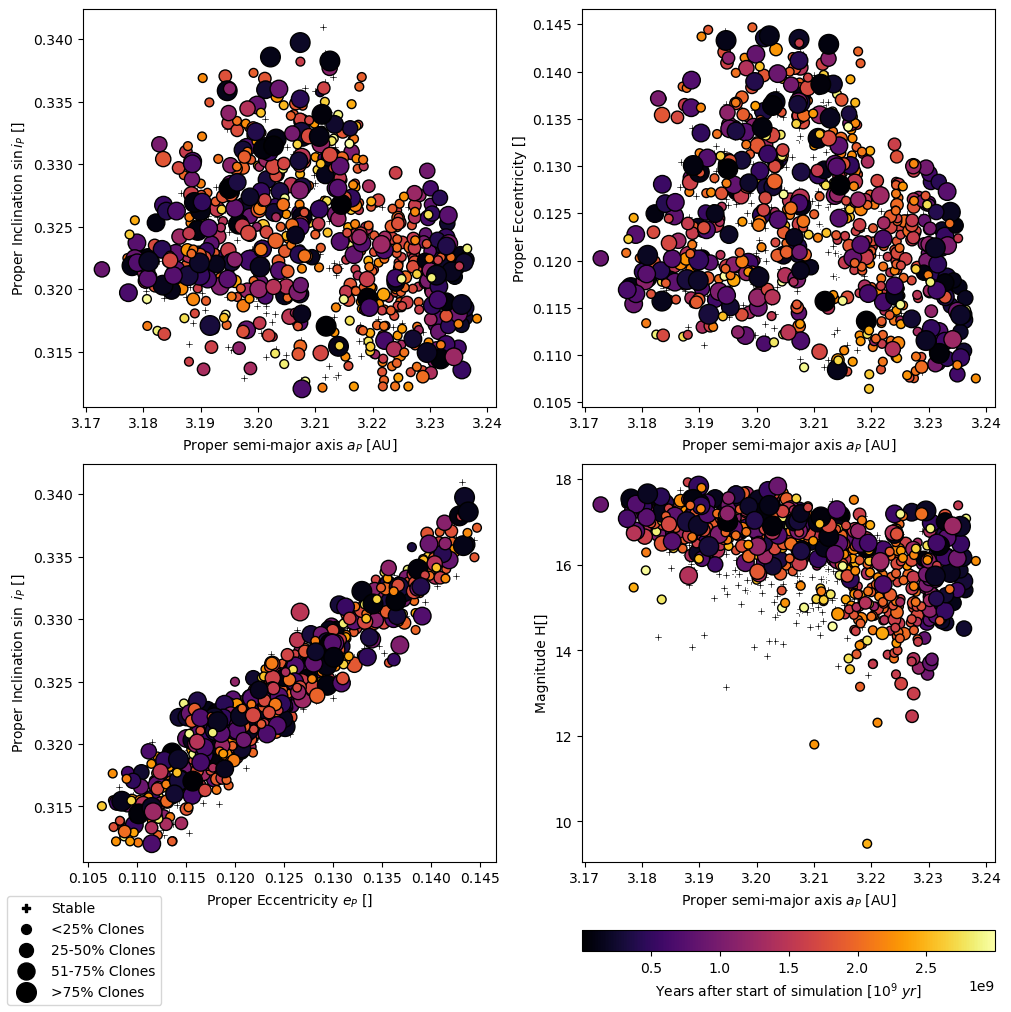

In [15]:
fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 1])
flash_plot(ax1, luth_fam, 'e_P')
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper Eccentricity []")

ax2 = fig.add_subplot(spec[0, 0])
flash_plot(ax2, luth_fam, 'sineI_P')
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper Inclination $\sin i_P$ []")

ax3 = fig.add_subplot(spec[1, 0])
flash_plot(ax3, luth_fam, 'sineI_P', 'e_P')
ax3.set_xlabel("Proper Eccentricity $e_P$ []")
ax3.set_ylabel("Proper Inclination $\sin ~i_P$ []")

ax4 = fig.add_subplot(spec[1, 1])
esc, stab = flash_plot(ax4, luth_fam, 'abs_mag')  
ax4.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax4.set_ylabel("Magnitude H[]")

cb = fig.colorbar(esc, label=xlabel_time, location='bottom')
esc_elements = esc.legend_elements("sizes", num=4)
stab_elements = stab.legend_elements("sizes", num=1)
        
fig.legend(handles = stab_elements[0] + esc_elements[0], 
           labels=['Stable', '<25% Clones', '25-50% Clones','51-75% Clones', '>75% Clones'],
           loc='lower left')

plt.savefig(plot_dir / "escape_4.png", dpi=300)
plt.show()

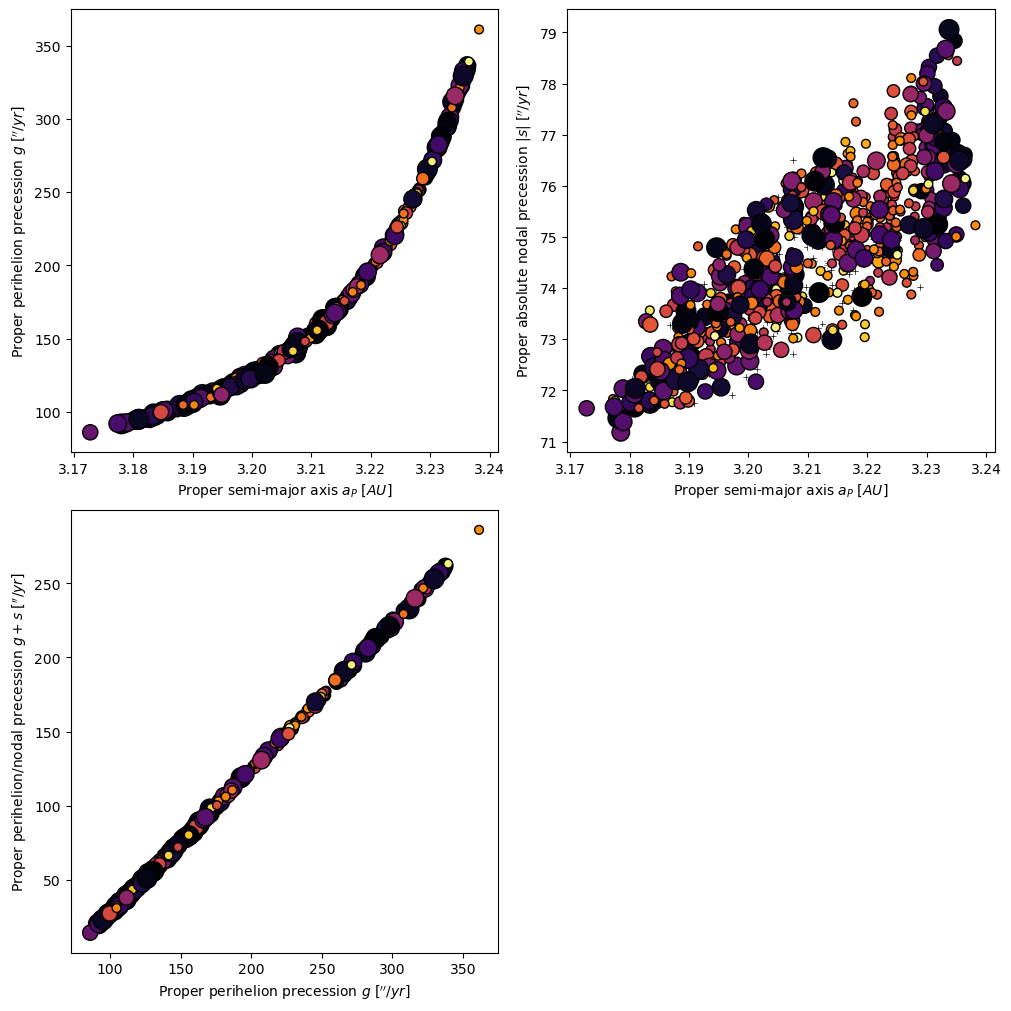

In [37]:
fig = plt.figure(figsize=(10, 10), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
flash_plot(ax1, luth_fam, 'g', 'a_P')
ax1.set_xlabel("Proper semi-major axis $a_P$ [$AU$]")
ax1.set_ylabel("Proper perihelion precession $g$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 1])
flash_plot(ax2, luth_fam, 'abs_s', 'a_P' )
ax2.set_xlabel("Proper semi-major axis $a_P$ [$AU$]")
ax2.set_ylabel("Proper absolute nodal precession $|s|$ [$''/yr$]")

ax3 = fig.add_subplot(spec[1, 0])
flash_plot(ax3, luth_fam, 'g_s', 'g')
ax3.set_xlabel("Proper perihelion precession $g$ [$''/ yr$]")
ax3.set_ylabel("Proper perihelion/nodal precession $g+s$ [$''/yr$]")

plt.savefig(plot_dir / "escape_3d.png", dpi=300)
plt.show()

# Proper Elements Histograms


In [ ]:
def hist_ratio(data, col_name, x_label):
    stable_cnts, bins = np.histogram(data[data.integration_year == 0][col_name],bins='auto')  
    escp_cnts, bins = np.histogram(data[data.integration_year != 0][col_name],bins=bins)
    ratio = ((stable_cnts)/(stable_cnts+escp_cnts+1.0e-40))*100

    fig = plt.figure(figsize=(8, 8))
    ax0 = plt.subplot(111)
    ax1 = ax0.twinx()
    ax0.hist([data[data.integration_year == 0][col_name], 
                  data[data.integration_year != 0][col_name]], bins=bins, stacked=True)
    ax0.set_ylabel("Frequency")
    ax0.set_xlabel(x_label)
    ax0.legend(labels=['Stable', 'Escaped'])


    ax1.plot(bins[:-1]+(bins[1]-bins[0])/2,ratio, c='grey', marker='+')
    ax1.set_ylim(0,100)
    ax1.set_ylabel("Asteroid Stability [%]")
    plt.show()
    

In [ ]:
hist_ratio(luth_fam, 'ideg', "Inclination [$\degree$]")

In [ ]:
hist_ratio(luth_fam, 'abs_mag', "Magnitude H[]")

In [ ]:
hist_ratio(luth_fam, 'a_P', "Semimajor Axis [AU]")

In [ ]:
hist_ratio(luth_fam, 'e_P', "Proper Eccentricity []")

# Escaped Asteroids SMA extremities



In [17]:
def ploto_loco(ax, ast_data, y_column, x_column, groupby, symbols, colors, edgecolors, legend=None):
    for last_sma, m_fam in ast_data.groupby(groupby):
        if legend:
            ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors=None, marker=symbols[last_sma], 
                        c=colors[last_sma], s=15, label=legend[last_sma])
        else:
            ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors=None, marker=symbols[last_sma], 
                        c=colors[last_sma], s=15)
            


In [24]:
#luth_fam['min_sma'] = ea_mmc3.min_val
#luth_fam['max_sma'] = ea_mmc3.max_val
a_min = 1.8
a_max = 3.95
# 1 = inner
# 2 = outer
# 3 = both
# 0 = stable
def inny_outy(esc):
    if esc.mean_min_val < a_min and esc.mean_max_val < a_max:
        return 1
    elif esc.mean_max_val > a_max and esc.mean_min_val > a_min:
        return 2
    elif esc.mean_max_val > a_max and esc.mean_min_val < a_min:
        return 3
    else:
        return 0

max_min_sma = ea_mmc3.loc[ea_mmc3.parameter == 6][['min_val', 'max_val']]
mean_sma = max_min_sma.groupby(by=max_min_sma.index).mean(['min_val','max_val'])

luth_fam['mean_min_val'] = mean_sma.min_val
luth_fam['mean_max_val'] = mean_sma.max_val
luth_fam['last_sma'] = luth_fam.apply(inny_outy, axis=1)

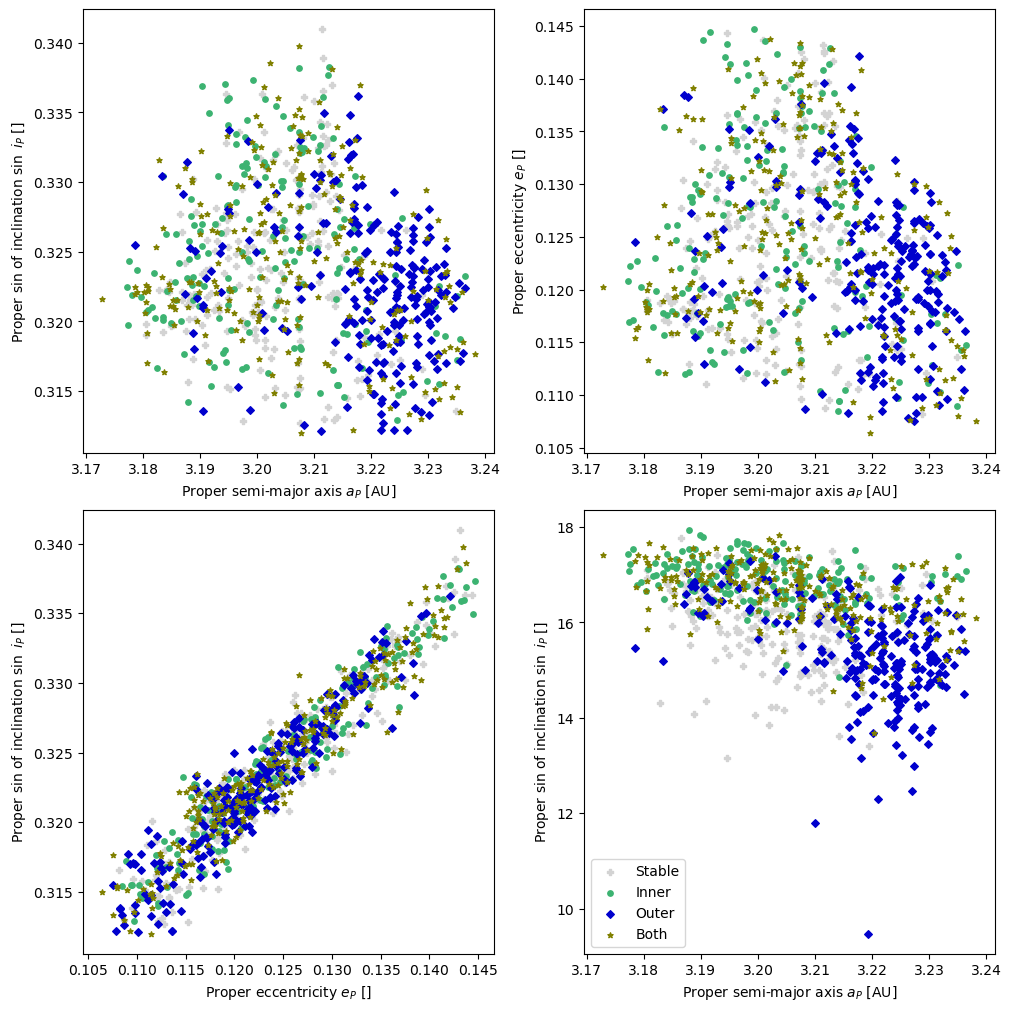

In [39]:
symbols = ['P','o','D', '*']
colors = ['lightgray','mediumseagreen', 'mediumblue', 'olive']
edgecolors = ['white','black','black','black']
legend = ['Stable', 'Inner', 'Outer', 'Both']

fig = plt.figure(figsize=(10, 10), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 1])
ploto_loco(ax1, luth_fam, 'e_P', 'a_P', 'last_sma', symbols, colors, edgecolors)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper eccentricity $e_P$ []")


ax2 = fig.add_subplot(spec[0, 0])
ploto_loco(ax2, luth_fam, 'sineI_P', 'a_P', 'last_sma', symbols, colors, edgecolors)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper sin of inclination $\sin ~i_P$ []")

ax3 = fig.add_subplot(spec[1, 0])
ploto_loco(ax3, luth_fam, 'sineI_P', 'e_P', 'last_sma', symbols, colors, edgecolors)
ax3.set_xlabel("Proper eccentricity $e_P$ []")
ax3.set_ylabel("Proper sin of inclination $\sin ~i_P$ []")

ax4 = fig.add_subplot(spec[1, 1])
ploto_loco(ax4, luth_fam, 'abs_mag', 'a_P', 'last_sma', symbols, colors, edgecolors, legend)
ax4.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax4.set_ylabel("Proper sin of inclination $\sin ~i_P$ []")
ax4.legend(loc='lower left')

plt.savefig(plot_dir / "dest_aei.png", dpi=300)
plt.show()



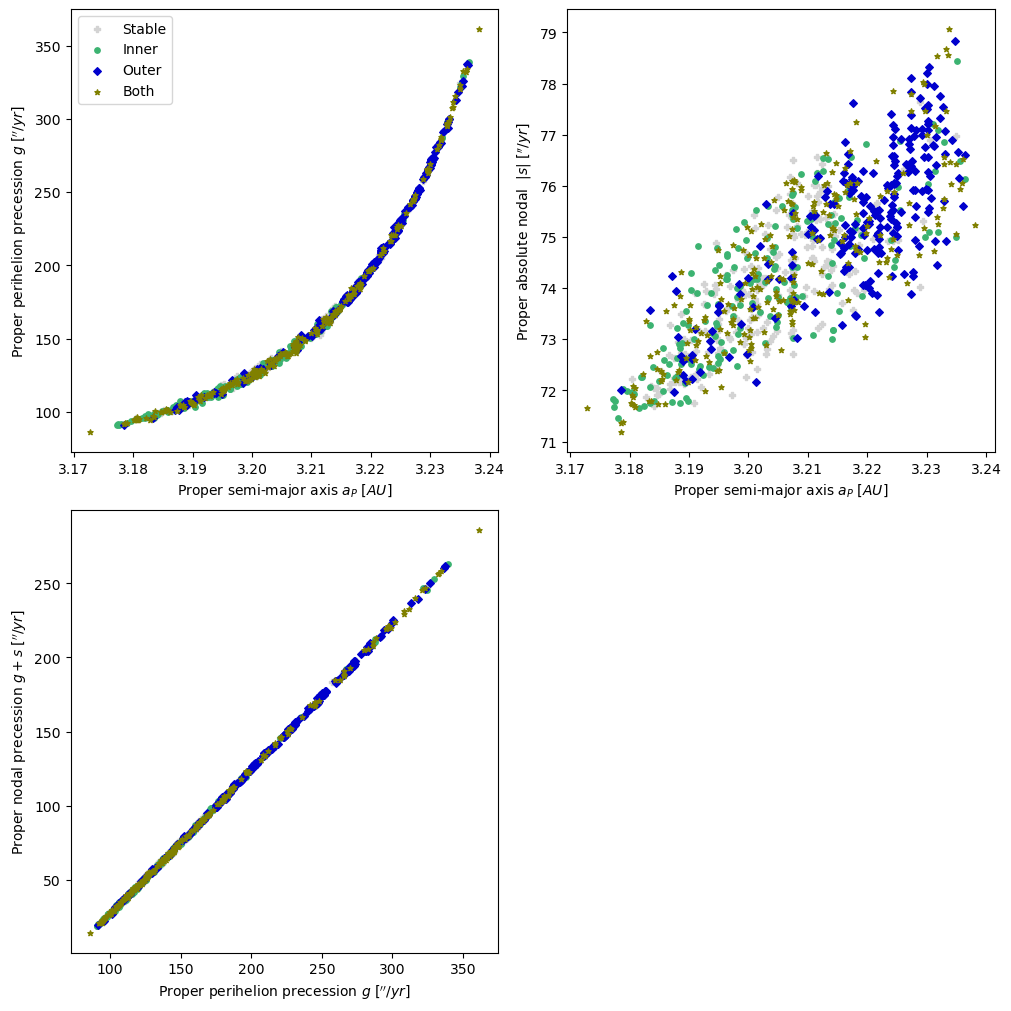

In [40]:
luth_fam['g_s'] = luth_fam.g + luth_fam.s
luth_fam['abs_s'] = np.absolute(luth_fam.s)

symbols = ['P','o','D', '*']
colors = ['lightgray','mediumseagreen', 'mediumblue', 'olive']
edgecolors = ['white','black','black','black']
legend = ['Stable', 'Inner', 'Outer', 'Both']

fig = plt.figure(figsize=(10, 10), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ploto_loco(ax1, luth_fam, 'g', 'a_P', 'last_sma', symbols, colors, edgecolors, legend)
ax1.legend()
ax1.set_xlabel("Proper semi-major axis $a_P$ [$AU$]")
ax1.set_ylabel("Proper perihelion precession $g$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 1])
ploto_loco(ax2, luth_fam, 'abs_s', 'a_P', 'last_sma', symbols, colors, edgecolors, legend)
ax2.set_xlabel("Proper semi-major axis $a_P$ [$AU$]")
ax2.set_ylabel("Proper absolute nodal  $|s|$ [$''/yr$]")

ax3 = fig.add_subplot(spec[1, 0])
ploto_loco(ax3, luth_fam, 'g_s', 'g', 'last_sma', symbols, colors, edgecolors, legend)
ax3.set_xlabel("Proper perihelion precession $g$ [$''/ yr$]")
ax3.set_ylabel("Proper nodal precession $g+s$ [$''/yr$]")

plt.savefig(plot_dir / "dest_ags.png", dpi=300)
plt.show()



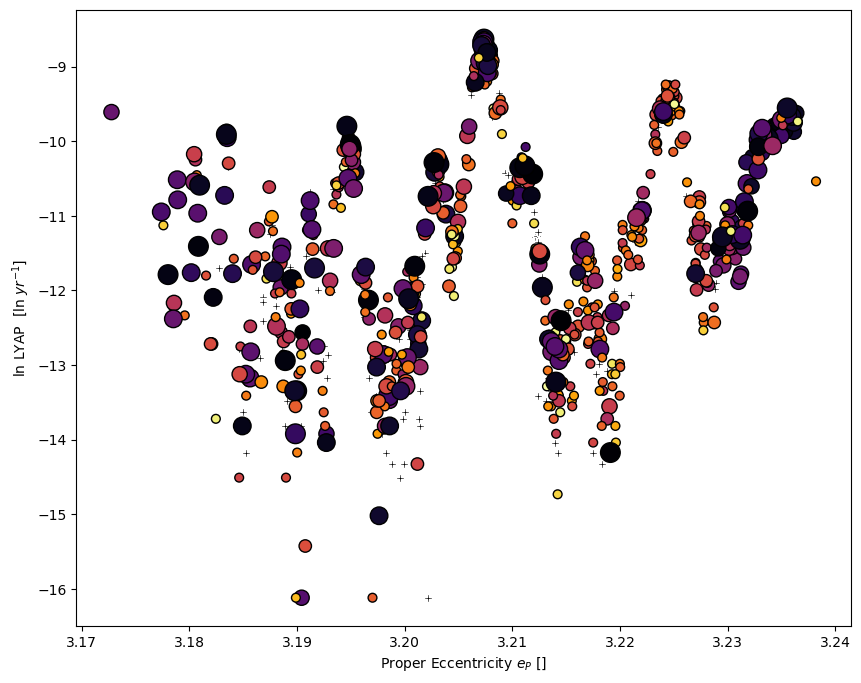

In [21]:
luth_fam['ln_lyap'] = np.log(1/(luth_fam.lyap_time*1000))

fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ln_lyap', 'a_P')
    
plt.xlabel("Proper Eccentricity $e_P$ []")
plt.ylabel("ln LYAP  [ln $yr^{-1}$]")
plt.savefig(plot_dir / "escape_ei.png", dpi=300)
plt.show()

In [25]:
luth_fam

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,...,diam,integration_year,quartiles,graph_symbol,mean_min_val,mean_max_val,last_sma,g_s,abs_s,ln_lyap
ast_name,,,,,,,,,,,,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,62.310603,193.693422,-75.178531,500.0,-10,0.328133,...,85.836005,2.467311e+09,1.0,o,2.744988,13.728663,2,118.514891,75.178531,-13.122363
11911,11.80,3.210027,0.132169,0.330567,62.579772,151.725694,-75.054158,48.8,-10,0.336904,...,29.489642,2.288327e+09,1.0,o,3.133313,43.646144,2,76.671536,75.054158,-10.795486
16794,13.45,3.229767,0.120773,0.321221,62.006408,267.491465,-76.751030,87.7,-10,0.327018,...,13.793342,9.323623e+08,2.0,o,2.644265,15.013014,2,190.740435,76.751030,-11.381677
17840,12.46,3.227073,0.122213,0.322861,62.084582,243.861008,-76.365994,123.5,-10,0.328751,...,21.760531,1.555482e+09,2.0,o,2.944280,29.063317,2,167.495014,76.365994,-11.723996
26558,13.15,3.194646,0.115763,0.319342,63.032408,116.103022,-72.503135,27.1,-10,0.325035,...,15.836875,0.000000e+00,NaN,.,NaN,NaN,0,43.599887,72.503135,-10.207289
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021TA55,17.17,3.194082,0.114092,0.317706,63.048004,115.703831,-72.437569,53.8,-10,0.323309,...,2.486964,2.539433e+09,1.0,o,0.000000,3.890054,1,43.266262,72.437569,-10.893029
2021TZ86,17.04,3.199622,0.138950,0.332601,62.884899,122.499167,-74.946763,625.0,-10,0.339060,...,2.640399,3.910643e+08,4.0,o,0.000000,2.700328,1,47.552404,74.946763,-13.345507
2021UJ60,17.20,3.194881,0.135663,0.334094,63.027298,111.565516,-73.689163,24.4,-10,0.340644,...,2.452842,1.150835e+09,3.0,o,0.000000,2.479319,1,37.876353,73.689163,-10.102338


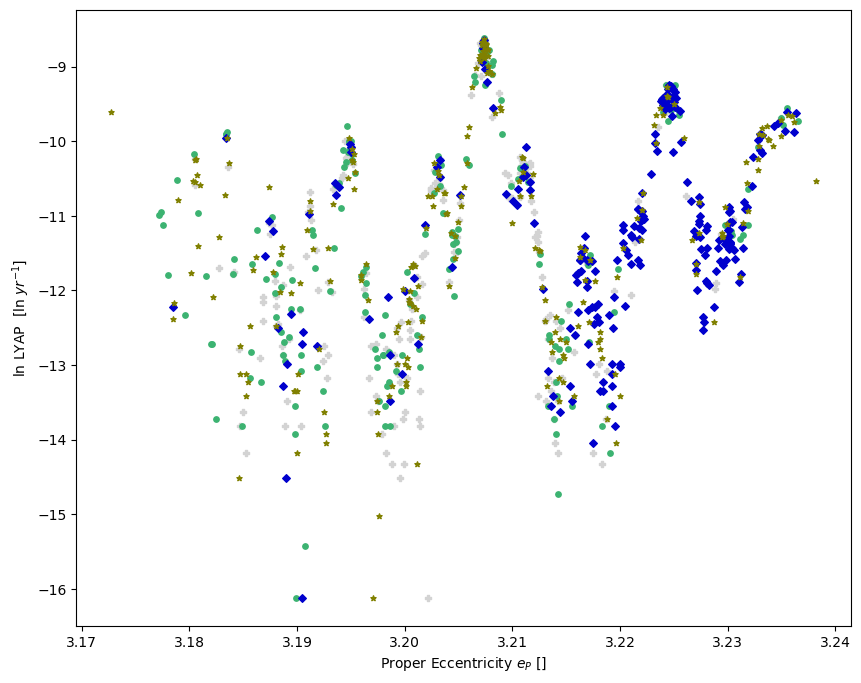

In [26]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

ploto_loco(ax, luth_fam, 'ln_lyap', 'a_P', 'last_sma', symbols, colors, edgecolors, legend)

plt.xlabel("Proper Eccentricity $e_P$ []")
plt.ylabel("ln LYAP  [ln $yr^{-1}$]")
plt.savefig(plot_dir / "escape_ei.png", dpi=300)
plt.show()